In [1]:
import pandas as pd
import numpy as np

## Dataset Description and Preprocessing

### 1. Original Data Source

The dataset was obtained from Mendeley Data, titled *Hourly Electricity Generation, Demand, Load Shedding, and Fuel Mix Dataset for Bangladesh (2015–2026)*. The original electricity-system records were collected from the Power Grid Company of Bangladesh (PGCB) ERP portal using a Python-based web-scraping procedure.

The dataset contains approximately 94,000 hourly observations covering April 2015 to March 2026.

**Dataset Reference:**
Shekh, M. I., & Rafi, R. H. (2026). *Hourly Electricity Generation, Demand, Load Shedding, and Fuel Mix Dataset for Bangladesh (2015–2026)*. Mendeley Data. https://doi.org/10.17632/vpk8spw2mm.1

### 2. Data Provider and Collection Period

* **Original Data Provider:** Power Grid Company of Bangladesh (PGCB).
* **Data Repository:** Mendeley Data.
* **Historical Coverage:** April 2015 – March 2026.
* **Publication Date:** March 30, 2026.
* **Data Collection Method:** Automated web scraping of publicly available PGCB electricity-system records.

### 3. Electricity Demand and Load Shedding

**Electricity Demand (MW):** Represents the recorded national electricity demand at a particular hour.

**Load Shedding (MW):** Represents the estimated electricity supply deficit resulting in unmet demand.

These variables were selected because historical electricity demand and load shedding may provide useful information for predicting electricity demand in the subsequent hour.

### 4. Data Cleaning and Preprocessing

The original dataset was processed to prepare it for time-series forecasting. The following procedures were applied:

* The date and time information was converted into a standardized datetime format.
* Records were sorted chronologically.
* Duplicate timestamps were identified and handled.
* Invalid datetime values were removed.
* Only three relevant variables were retained: `date`, `demand`, and `load_shedding`.
* Other variables, including electricity generation by fuel source and electricity imports, were excluded because they were not used in the forecasting model.

The resulting dataset was used to develop machine-learning and deep-learning models for next-hour electricity-demand forecasting.

### 5. Record Exclusion Criteria

Records were excluded only when they failed to satisfy the preprocessing requirements, such as containing invalid timestamps or duplicate datetime entries.

Other variables were omitted from the modeling dataset because they were outside the scope of this study.

The exclusion of additional variables should be distinguished from the removal of entire observations. Only the relevant datetime, electricity-demand, and load-shedding information was retained for model development.

### 6. Annual Record Exclusion Analysis

The number of records excluded during preprocessing was calculated separately for each year.

The annual exclusion count was determined using:

$$
N_{\text{excluded},y}
=
N_{\text{original},y}
-
N_{\text{retained},y}
$$

The exclusion analysis was conducted to assess the temporal consistency of the dataset and identify years with substantial data loss.

The annual record counts and exclusion reasons were determined from the original and cleaned datasets.


In [2]:
df_ele = pd.read_csv('D:\\Users\\Md Mahfuzur Rahman\\Desktop\\Research\\pgcb_V1_raw.csv')

In [3]:
df_ele.head(5)

,datetime,generation_mw,demand_mw,load_shedding,gas,liquid_fuel,coal,hydro,solar,wind,india_bheramara_hvdc,india_tripura,india_adani,nepal,remarks
0,2015-04-17 18:30:00,5862,5862,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN
1,2015-04-17 19:00:00,6598,6598,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN
2,2015-04-17 19:30:00,6639,6639,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN
3,2015-04-17 20:00:00,6683,6683,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,NaN
4,2015-04-17 21:00:00,6782,6782,0,0,0,0,0,NaN,NaN,0,0,NaN,NaN,Evening_Peak


In [4]:
df_ele.shape

(94934, 15)

## Weather Data Source and Retrieval

Hourly weather observations were obtained from [Meteostat](https://meteostat.net/en/) for selected locations in Bangladesh. Data were collected for the period from **January 1, 2020, through December 31, 2025**.

The Meteostat station identifiers used were:

| Location | Station ID |
|---|---:|
| Dhaka | 41923 |
| Chattogram | 41978 |
| Rajshahi | 41895 |
| Khulna | 41947 |
| Sylhet | 41891 |
| Barishal | 41950 |
| Rangpur | 41859 |

For each location, the station ID was supplied to Meteostat’s hourly-data interface, along with the start and end dates. The returned observations were fetched into a pandas DataFrame. The analysis retained the observation time (`time`), temperature (`temp`), and wind speed (`wspd`) fields. Meteostat’s standard units are degrees Celsius for temperature and kilometres per hour for wind speed.

The following example retrieves hourly data for Rangpur (station **41859**):


In [53]:
df_barishal = pd.read_csv('D:\\Users\\Md Mahfuzur Rahman\\Desktop\\Research\\data\\barishal_hourly_weather_data.csv')
print(df_barishal.head(5))

                  time  temp  rhum  prcp  snwd  wdir  wspd  wpgt    pres  \
0  2020-01-01 00:00:00  13.9   100   NaN   NaN   NaN   0.0   NaN  1017.4   
1  2020-01-01 01:00:00  14.8    99   NaN   NaN   NaN   0.0   NaN  1018.3   
2  2020-01-01 02:00:00  16.1    94   NaN   NaN   NaN   0.0   NaN  1019.2   
3  2020-01-01 03:00:00  17.3    96   NaN   NaN   NaN   0.0   NaN  1020.1   
4  2020-01-01 04:00:00  19.4    83   NaN   NaN   NaN   0.0   NaN  1019.9   

   tsun  cldc  coco  
0   NaN   NaN   5.0  
1   NaN   NaN   1.0  
2   NaN   NaN   1.0  
3   NaN   NaN   1.0  
4   NaN   NaN   1.0  


In [6]:
df_sylhet = pd.read_csv('D:\\Users\\Md Mahfuzur Rahman\\Desktop\\Research\\data\\sylhet_hourly_weather_data.csv')
print(df_sylhet.head(5))

                  time  temp  rhum  prcp  snwd   wdir  wspd  wpgt    pres  \
0  2020-01-01 00:00:00  17.8  74.0   NaN   NaN   90.0   7.6   NaN  1017.3   
1  2020-01-01 03:00:00  20.2  59.0   NaN   NaN   90.0   3.6   NaN  1019.8   
2  2020-01-01 06:00:00  22.1  60.0   NaN   NaN   90.0   3.6   NaN  1019.5   
3  2020-01-01 09:00:00  24.0  54.0   NaN   NaN  100.0  14.8   NaN  1017.2   
4  2020-01-01 12:00:00  20.8  74.0   NaN   NaN   90.0   7.6   NaN  1018.2   

   tsun  cldc  coco  
0   NaN   8.0   NaN  
1   NaN   6.0   NaN  
2   NaN   6.0   NaN  
3   NaN   6.0   NaN  
4   NaN   3.0   NaN  


In [7]:
df_khulna = pd.read_csv('D:\\Users\\Md Mahfuzur Rahman\\Desktop\\Research\\data\\khulna_hourly_weather_data.csv')
print(df_khulna.head(5))

                  time  temp  rhum  prcp  snwd   wdir  wspd  wpgt    pres  \
0  2020-01-01 00:00:00  14.7    94   NaN   NaN  354.0   3.7   NaN  1017.4   
1  2020-01-01 01:00:00  15.2    93   NaN   NaN  359.0   3.7   NaN  1018.3   
2  2020-01-01 02:00:00  15.8    90   NaN   NaN    1.0   1.8   NaN  1019.3   
3  2020-01-01 03:00:00  16.4    96   NaN   NaN    NaN   0.0   NaN  1020.2   
4  2020-01-01 04:00:00  18.4    80   NaN   NaN  359.0   1.8   NaN  1020.0   

   tsun  cldc  coco  
0   NaN   NaN   1.0  
1   NaN   NaN   1.0  
2   NaN   NaN   2.0  
3   NaN   NaN   1.0  
4   NaN   NaN   1.0  


In [8]:
df_rajshahi = pd.read_csv('D:\\Users\\Md Mahfuzur Rahman\\Desktop\\Research\\data\\rajshahi_hourly_weather_data.csv')
print(df_rajshahi.head(5))

                  time  temp  rhum  prcp  snwd  wdir  wspd  wpgt    pres  \
0  2020-01-01 00:00:00  12.3  92.0   NaN   NaN     0   0.0   NaN  1017.3   
1  2020-01-01 03:00:00  15.1  87.0   NaN   NaN   330   3.6   NaN  1020.9   
2  2020-01-01 06:00:00  22.3  63.0   NaN   NaN   350   3.6   NaN  1020.2   
3  2020-01-01 09:00:00  24.0  61.0   NaN   NaN   360   3.6   NaN  1017.6   
4  2020-01-01 12:00:00  21.0  69.0   NaN   NaN   310   5.4   NaN  1018.3   

   tsun  cldc  coco  
0   NaN   NaN   NaN  
1   NaN   5.0   NaN  
2   NaN   5.0   NaN  
3   NaN   8.0   NaN  
4   NaN   8.0   NaN  


In [9]:
df_chattogram = pd.read_csv('D:\\Users\\Md Mahfuzur Rahman\\Desktop\\Research\\data\\chattogram_hourly_weather_data.csv')
print(df_chattogram.head(5))

                  time  temp  rhum  prcp  snwd   wdir  wspd  wpgt    pres  \
0  2020-01-01 00:00:00  18.0  88.0   NaN   NaN    0.0   0.0   NaN  1016.7   
1  2020-01-01 01:00:00  18.0  94.0   NaN   NaN    0.0   0.0   NaN  1017.0   
2  2020-01-01 02:00:00  18.0  94.0   NaN   NaN    0.0   0.0   NaN  1019.0   
3  2020-01-01 03:00:00  22.7  66.0   NaN   NaN    0.0   0.0   NaN  1019.5   
4  2020-01-01 04:00:00  24.0  61.0   NaN   NaN  270.0   3.6   NaN  1020.0   

   tsun  cldc  coco  
0   NaN   2.0   NaN  
1   NaN   NaN   5.0  
2   NaN   NaN   5.0  
3   NaN   6.0   NaN  
4   NaN   NaN   5.0  


In [10]:
df_dhaka = pd.read_csv('D:\\Users\\Md Mahfuzur Rahman\\Desktop\\Research\\data\\dhaka_hourly_weather_data.csv')
print(df_dhaka.head(5))

                  time  temp  rhum  prcp  snwd   wdir  wspd  wpgt    pres  \
0  2020-01-01 00:00:00  15.3    92   NaN   NaN    0.0   0.0   NaN  1016.5   
1  2020-01-01 01:00:00  16.3    93   NaN   NaN  351.0   1.8   NaN  1017.7   
2  2020-01-01 02:00:00  17.1    87   NaN   NaN    NaN   0.0   NaN  1018.8   
3  2020-01-01 03:00:00  20.2    68   NaN   NaN  270.0   3.6   NaN  1019.5   
4  2020-01-01 04:00:00  20.0    73   NaN   NaN    NaN   0.0   NaN  1019.6   

   tsun  cldc  coco  
0   NaN   2.0   1.0  
1   NaN   NaN   3.0  
2   NaN   NaN   2.0  
3   NaN   3.0   1.0  
4   NaN   NaN   2.0  


In [11]:
print('Barishal: ', df_barishal.shape)
print('Sylhet: ', df_sylhet.shape)
print('Khulna: ', df_khulna.shape)
print('Rajshahi: ', df_rajshahi.shape)
print('Chattogram: ', df_chattogram.shape)
print('Dhaka: ', df_dhaka.shape)


Barishal:  (52608, 12)
Sylhet:  (46045, 12)
Khulna:  (52344, 12)
Rajshahi:  (45982, 12)
Chattogram:  (51737, 12)
Dhaka:  (52608, 12)


In [12]:
# Merge all weather dataframes by time with renamed columns
# Start with Rangpur
df_merged = df_dhaka[['time', 'temp', 'wspd']].rename(
    columns={'temp': 'temp_dhaka', 'wspd': 'wspd_dhaka'}
)

# Merge with other regions
regions = [
    ('Barishal', df_barishal),
    ('Chattogram', df_chattogram),
    ('Khulna', df_khulna),
    ('Rajshahi', df_rajshahi),
    ('Sylhet', df_sylhet)
]

for region_name, df_region in regions:
    df_temp = df_region[['time', 'temp', 'wspd']].rename(
        columns={
            'temp': f'temp_{region_name.lower()}',
            'wspd': f'wspd_{region_name.lower()}'
        }
    )
    df_merged = df_merged.merge(df_temp, on='time', how='outer')

print("Merged dataframe shape:", df_merged.shape)
print("\nColumns:", df_merged.columns.tolist())
print("\nFirst few rows:")
df_merged.head()

Merged dataframe shape: (52608, 13)

Columns: ['time', 'temp_dhaka', 'wspd_dhaka', 'temp_barishal', 'wspd_barishal', 'temp_chattogram', 'wspd_chattogram', 'temp_khulna', 'wspd_khulna', 'temp_rajshahi', 'wspd_rajshahi', 'temp_sylhet', 'wspd_sylhet']

First few rows:


,time,temp_dhaka,wspd_dhaka,temp_barishal,wspd_barishal,temp_chattogram,wspd_chattogram,temp_khulna,wspd_khulna,temp_rajshahi,wspd_rajshahi,temp_sylhet,wspd_sylhet
0,2020-01-01 00:00:00,15.3,0.0,13.9,0.0,18.0,0.0,14.7,3.7,12.3,0.0,17.8,7.6
1,2020-01-01 01:00:00,16.3,1.8,14.8,0.0,18.0,0.0,15.2,3.7,NaN,NaN,NaN,NaN
2,2020-01-01 02:00:00,17.1,0.0,16.1,0.0,18.0,0.0,15.8,1.8,NaN,NaN,NaN,NaN
3,2020-01-01 03:00:00,20.2,3.6,17.3,0.0,22.7,0.0,16.4,0.0,15.1,3.6,20.2,3.6
4,2020-01-01 04:00:00,20.0,0.0,19.4,0.0,24.0,3.6,18.4,1.8,NaN,NaN,NaN,NaN


In [13]:
df_merged.head(5)

,time,temp_dhaka,wspd_dhaka,temp_barishal,wspd_barishal,temp_chattogram,wspd_chattogram,temp_khulna,wspd_khulna,temp_rajshahi,wspd_rajshahi,temp_sylhet,wspd_sylhet
0,2020-01-01 00:00:00,15.3,0.0,13.9,0.0,18.0,0.0,14.7,3.7,12.3,0.0,17.8,7.6
1,2020-01-01 01:00:00,16.3,1.8,14.8,0.0,18.0,0.0,15.2,3.7,NaN,NaN,NaN,NaN
2,2020-01-01 02:00:00,17.1,0.0,16.1,0.0,18.0,0.0,15.8,1.8,NaN,NaN,NaN,NaN
3,2020-01-01 03:00:00,20.2,3.6,17.3,0.0,22.7,0.0,16.4,0.0,15.1,3.6,20.2,3.6
4,2020-01-01 04:00:00,20.0,0.0,19.4,0.0,24.0,3.6,18.4,1.8,NaN,NaN,NaN,NaN


In [14]:
df_merged.shape

(52608, 13)

In [15]:
df_merged.dropna(inplace=True)

In [16]:
df_merged.shape

(45697, 13)

In [17]:
df_merged.head()

,time,temp_dhaka,wspd_dhaka,temp_barishal,wspd_barishal,temp_chattogram,wspd_chattogram,temp_khulna,wspd_khulna,temp_rajshahi,wspd_rajshahi,temp_sylhet,wspd_sylhet
0,2020-01-01 00:00:00,15.3,0.0,13.9,0.0,18.0,0.0,14.7,3.7,12.3,0.0,17.8,7.6
3,2020-01-01 03:00:00,20.2,3.6,17.3,0.0,22.7,0.0,16.4,0.0,15.1,3.6,20.2,3.6
6,2020-01-01 06:00:00,25.6,5.4,23.3,0.0,27.3,3.6,21.8,1.8,22.3,3.6,22.1,3.6
9,2020-01-01 09:00:00,28.0,0.0,24.6,1.8,27.3,3.6,23.6,3.7,24.0,3.6,24.0,14.8
12,2020-01-01 12:00:00,20.8,0.0,19.9,0.0,23.5,0.0,20.3,0.0,21.0,5.4,20.8,7.6


In [18]:
import datetime 
df_merged['datetime']=pd.to_datetime(df_merged['time'])

In [19]:
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45697 entries, 0 to 52607
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   time             45697 non-null  object        
 1   temp_dhaka       45697 non-null  float64       
 2   wspd_dhaka       45697 non-null  float64       
 3   temp_barishal    45697 non-null  float64       
 4   wspd_barishal    45697 non-null  float64       
 5   temp_chattogram  45697 non-null  float64       
 6   wspd_chattogram  45697 non-null  float64       
 7   temp_khulna      45697 non-null  float64       
 8   wspd_khulna      45697 non-null  float64       
 9   temp_rajshahi    45697 non-null  float64       
 10  wspd_rajshahi    45697 non-null  float64       
 11  temp_sylhet      45697 non-null  float64       
 12  wspd_sylhet      45697 non-null  float64       
 13  datetime         45697 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(12), object(1

In [20]:
df_merged.head(5)

,time,temp_dhaka,wspd_dhaka,temp_barishal,wspd_barishal,temp_chattogram,wspd_chattogram,temp_khulna,wspd_khulna,temp_rajshahi,wspd_rajshahi,temp_sylhet,wspd_sylhet,datetime
0,2020-01-01 00:00:00,15.3,0.0,13.9,0.0,18.0,0.0,14.7,3.7,12.3,0.0,17.8,7.6,2020-01-01 00:00:00
3,2020-01-01 03:00:00,20.2,3.6,17.3,0.0,22.7,0.0,16.4,0.0,15.1,3.6,20.2,3.6,2020-01-01 03:00:00
6,2020-01-01 06:00:00,25.6,5.4,23.3,0.0,27.3,3.6,21.8,1.8,22.3,3.6,22.1,3.6,2020-01-01 06:00:00
9,2020-01-01 09:00:00,28.0,0.0,24.6,1.8,27.3,3.6,23.6,3.7,24.0,3.6,24.0,14.8,2020-01-01 09:00:00
12,2020-01-01 12:00:00,20.8,0.0,19.9,0.0,23.5,0.0,20.3,0.0,21.0,5.4,20.8,7.6,2020-01-01 12:00:00


In [21]:
df_merged.to_csv('merged_all_divisions_weather_data.csv', index=False)

## Aggregating Division-Level Weather Data

Electricity demand is recorded for Bangladesh as a whole, while weather observations are available separately for individual divisions. To combine these sources, temperature and wind speed are averaged across the available divisions for each timestamp. This produces one nationwide mean temperature and wind-speed value per time period, which can be aligned with the national electricity-demand record.

For timestamp \(t\), the averages are calculated as:

$$
\overline{T}_t = \frac{1}{n_t}\sum_{i=1}^{n_t} T_{i,t},
\qquad
\overline{W}_t = \frac{1}{n_t}\sum_{i=1}^{n_t} W_{i,t}
$$

where \(T_{i,t}\) and \(W_{i,t}\) are the temperature and wind speed for division \(i\) at time \(t\), and \(n_t\) is the number of divisions with available observations at that time.

This approach represents nationwide weather conditions with a single mean temperature and wind-speed value for each timestamp. These aggregated weather variables can then be used alongside national electricity demand in the forecasting analysis. Because this is a simple average, each division contributes equally, regardless of its population or electricity consumption.

In [22]:
# Create new dataset with mean of all temps and wspds with datetime as index
df_weather_avg = pd.DataFrame()

# Calculate mean temperature across all regions
temp_columns = [col for col in df_merged.columns if col.startswith('temp_')]
df_weather_avg['temp_mean'] = (df_merged[temp_columns].mean(axis=1)).round(2)

# Calculate mean wind speed across all regions
wspd_columns = [col for col in df_merged.columns if col.startswith('wspd_')]
df_weather_avg['wspd_mean'] = (df_merged[wspd_columns].mean(axis=1)).round(2)

# Set time as index and convert to datetime
df_weather_avg.index = pd.to_datetime(df_merged['time'])
df_weather_avg.index.name = 'datetime'

print("New dataset shape:", df_weather_avg.shape)
print("\nColumns:", df_weather_avg.columns.tolist())
print("\nFirst few rows:")
print(df_weather_avg.head(10))
print("\nDataset info:")
print(df_weather_avg.info())

New dataset shape: (45697, 2)

Columns: ['temp_mean', 'wspd_mean']

First few rows:
                     temp_mean  wspd_mean
datetime                                 
2020-01-01 00:00:00      15.33       1.88
2020-01-01 03:00:00      18.65       1.80
2020-01-01 06:00:00      23.73       3.00
2020-01-01 09:00:00      25.25       4.58
2020-01-01 12:00:00      21.05       2.17
2020-01-01 15:00:00      18.82       0.30
2020-01-01 18:00:00      17.67       1.80
2020-01-01 21:00:00      17.00       0.90
2020-01-02 00:00:00      16.63       2.12
2020-01-02 03:00:00      19.27       2.47

Dataset info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 45697 entries, 2020-01-01 00:00:00 to 2025-12-31 23:00:00
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   temp_mean  45697 non-null  float64
 1   wspd_mean  45697 non-null  float64
dtypes: float64(2)
memory usage: 1.0 MB
None


In [23]:
df_weather_avg.head(10)

,temp_mean,wspd_mean
datetime,,
2020-01-01 00:00:00,15.33,1.88
2020-01-01 03:00:00,18.65,1.80
2020-01-01 06:00:00,23.73,3.00
2020-01-01 09:00:00,25.25,4.58
2020-01-01 12:00:00,21.05,2.17
2020-01-01 15:00:00,18.82,0.30
2020-01-01 18:00:00,17.67,1.80
2020-01-01 21:00:00,17.00,0.90
2020-01-02 00:00:00,16.63,2.12


In [24]:
# Merge df_ele and df_weather_avg by datetime, keeping only demand_mw from df_ele
# Prepare df_ele with datetime as index
df_ele_prep = df_ele[['datetime', 'demand_mw','load_shedding']].copy()
df_ele_prep['datetime'] = pd.to_datetime(df_ele_prep['datetime'])
df_ele_prep = df_ele_prep.set_index('datetime')

# Merge the two datasets by index
df_combined = df_ele_prep.merge(df_weather_avg, left_index=True, right_index=True, how='inner')

print("Combined dataset shape:", df_combined.shape)
print("\nColumns:", df_combined.columns.tolist())
print("\nFirst few rows:")
print(df_combined.head(10))
print("\nDataset info:")
print(df_combined.info())

Combined dataset shape: (43526, 4)

Columns: ['demand_mw', 'load_shedding', 'temp_mean', 'wspd_mean']

First few rows:
                     demand_mw  load_shedding  temp_mean  wspd_mean
datetime                                                           
2020-01-01 03:00:00       5351              0      18.65       1.80
2020-01-01 06:00:00       5346              0      23.73       3.00
2020-01-01 09:00:00       6654              0      25.25       4.58
2020-01-01 12:00:00       6750              0      21.05       2.17
2020-01-01 15:00:00       6546              0      18.82       0.30
2020-01-01 18:00:00       8004              0      17.67       1.80
2020-01-01 21:00:00       8001              0      17.00       0.90
2020-01-02 03:00:00       5253              0      19.27       2.47
2020-01-02 06:00:00       5317              0      24.18       3.68
2020-01-02 09:00:00       6553              0      25.40       1.80

Dataset info:
<class 'pandas.core.frame.DataFrame'>
DatetimeInde

In [25]:
df_combined.head(10)

,demand_mw,load_shedding,temp_mean,wspd_mean
datetime,,,,
2020-01-01 03:00:00,5351,0,18.65,1.80
2020-01-01 06:00:00,5346,0,23.73,3.00
2020-01-01 09:00:00,6654,0,25.25,4.58
2020-01-01 12:00:00,6750,0,21.05,2.17
2020-01-01 15:00:00,6546,0,18.82,0.30
2020-01-01 18:00:00,8004,0,17.67,1.80
2020-01-01 21:00:00,8001,0,17.00,0.90
2020-01-02 03:00:00,5253,0,19.27,2.47
2020-01-02 06:00:00,5317,0,24.18,3.68


In [26]:
df_combined.shape

(43526, 4)

In [27]:
df_combined.index

DatetimeIndex(['2020-01-01 03:00:00', '2020-01-01 06:00:00',
               '2020-01-01 09:00:00', '2020-01-01 12:00:00',
               '2020-01-01 15:00:00', '2020-01-01 18:00:00',
               '2020-01-01 21:00:00', '2020-01-02 03:00:00',
               '2020-01-02 06:00:00', '2020-01-02 09:00:00',
               ...
               '2025-12-31 14:00:00', '2025-12-31 15:00:00',
               '2025-12-31 16:00:00', '2025-12-31 17:00:00',
               '2025-12-31 18:00:00', '2025-12-31 19:00:00',
               '2025-12-31 20:00:00', '2025-12-31 21:00:00',
               '2025-12-31 22:00:00', '2025-12-31 23:00:00'],
              dtype='datetime64[ns]', name='datetime', length=43526, freq=None)

In [28]:
df_combined.isnull().sum()

demand_mw        0
load_shedding    0
temp_mean        0
wspd_mean        0
dtype: int64

In [29]:
df_combined.describe().T

,count,mean,std,min,25%,50%,75%,max
demand_mw,43526.0,10616.557713,2563.847405,254.00,8814.00,10577.00,12440.00,121000.00
load_shedding,43526.0,155.782934,393.427289,0.00,0.00,0.00,88.00,13500.00
temp_mean,43526.0,26.248065,4.857516,11.05,23.48,27.25,29.62,38.38
wspd_mean,43526.0,4.816847,2.600309,0.00,2.97,4.28,6.25,40.13


### Screening Extreme Values

The 99th-percentile and largest-value checks are used to inspect unusually high observations in each numeric variable before deciding whether any records require further investigation.

- **Values above the 99th percentile:** For each numeric column, this identifies observations in its upper tail and reports their count and timestamps. Reviewing these rows can help reveal possible data-entry issues or unusual but valid events.
- **Largest values:** Listing the highest observations makes it easier to inspect the most extreme records directly and compare them with the expected ranges of the variables.

These checks are exploratory, not automatic outlier-removal rules. High values should be checked against the data context before excluding them; legitimate demand peaks, for example, may be important for forecasting.


In [30]:
# Get rows with values above 99th percentile
# Replace 'column_name' with your actual column to filter on

# For df_combined - example with a numeric column
for col in df_combined.select_dtypes(include='number').columns:
    print(f"\nAnalyzing column: {col}")

    # Calculate 99th percentile
    percentile_999 = df_combined[col].quantile(0.99)

    # Filter rows above 99th percentile
    top_1_percent = df_combined[df_combined[col] > percentile_999]

    print(f"99th Percentile Value: {percentile_999}")
    print(f"Total rows in df_combined: {len(df_combined)}")
    print(f"Rows above 99th percentile: {len(top_1_percent)}")
    print(f"Percentage: {len(top_1_percent) / len(df_combined) * 100:.2f}%")
    print(f"\nRows above 99th percentile:")
    print(top_1_percent.head(5).sort_values(by=col, ascending=False))


Analyzing column: demand_mw
99th Percentile Value: 15697.5
Total rows in df_combined: 43526
Rows above 99th percentile: 436
Percentage: 1.00%

Rows above 99th percentile:
                     demand_mw  load_shedding  temp_mean  wspd_mean
datetime                                                           
2023-04-16 21:00:00      16000           1291      28.22       2.10
2023-04-16 22:00:00      16000           1064      27.58       3.72
2023-04-17 20:00:00      15900            796      27.80       4.38
2023-04-16 20:00:00      15700           1207      28.20       4.93
2023-04-16 23:00:00      15700           1637      27.20       4.33

Analyzing column: load_shedding
99th Percentile Value: 1761.0
Total rows in df_combined: 43526
Rows above 99th percentile: 434
Percentage: 1.00%

Rows above 99th percentile:
                     demand_mw  load_shedding  temp_mean  wspd_mean
datetime                                                           
2022-06-25 14:00:00      11816           

In [31]:
# Get top 10 values for each column
# Method 1: Show top 10 values for each numeric column
numeric_columns = df_combined.select_dtypes(include=['number']).columns

print("Top 10 values for each column:")
print("="*50)
for col in numeric_columns:
    print(f"\n{col}:")
    print(df_combined[col].nlargest(50).values)


Top 10 values for each column:

demand_mw:
[121000 117000 111140  20587  17200  17150  17100  17100  17100  17000
  17000  16950  16900  16900  16850  16850  16850  16850  16830  16774
  16750  16750  16750  16750  16720  16700  16700  16700  16700  16700
  16700  16650  16650  16650  16625  16620  16600  16600  16600  16600
  16600  16600  16600  16600  16550  16550  16550  16520  16500  16500]

load_shedding:
[13500 11672  9098  9000  7852  7199  6905  6799  6539  5443  4847  4626
  4395  4171  3419  3287  3266  3215  3196  3143  3142  3042  3024  2976
  2962  2961  2939  2929  2920  2912  2884  2883  2856  2856  2837  2823
  2823  2822  2819  2815  2804  2799  2794  2790  2787  2769  2762  2757
  2744  2739]

temp_mean:
[38.38 37.85 37.72 37.7  37.7  37.53 37.47 37.37 37.37 37.3  37.28 37.23
 37.18 37.15 37.13 37.13 37.13 37.12 37.1  37.08 37.05 37.03 37.02 36.98
 36.93 36.93 36.92 36.9  36.88 36.87 36.85 36.85 36.83 36.83 36.8  36.8
 36.78 36.77 36.77 36.73 36.73 36.72 36.72 36.72 

In [32]:
df_cleaned = df_combined.copy()

In [33]:
df_cleaned.describe().T

,count,mean,std,min,25%,50%,75%,max
demand_mw,43526.0,10616.557713,2563.847405,254.00,8814.00,10577.00,12440.00,121000.00
load_shedding,43526.0,155.782934,393.427289,0.00,0.00,0.00,88.00,13500.00
temp_mean,43526.0,26.248065,4.857516,11.05,23.48,27.25,29.62,38.38
wspd_mean,43526.0,4.816847,2.600309,0.00,2.97,4.28,6.25,40.13


In [34]:
len(df_cleaned[df_cleaned['demand_mw'] < 3500])

47

In [35]:
# Remove rows that match any of the conditions
print(f"Original rows: {len(df_cleaned)}")

# Create mask for rows to remove
rows_to_remove_filtered = (
    (df_cleaned['demand_mw'] < 3500) |
    (df_cleaned['demand_mw'] > 20000) |
    (df_cleaned['load_shedding'] > 1500) |
    (df_cleaned['wspd_mean'] > 30)
)

# Show count before removal
print(f"Rows matching removal criteria: {rows_to_remove_filtered.sum()}")

# Remove the rows
df_cleaned = df_cleaned[~rows_to_remove_filtered]

print(f"\n{'='*50}")
print(f"Rows after removal: {len(df_cleaned)}")
print(f"{'='*50}")

print(f"\nUpdated data shape: {df_cleaned.shape}")
print(f"\nFirst few rows:")
print(df_cleaned.head())
print(f"\nStatistics:")
print(df_cleaned.describe().T)


Original rows: 43526
Rows matching removal criteria: 915

Rows after removal: 42611

Updated data shape: (42611, 4)

First few rows:
                     demand_mw  load_shedding  temp_mean  wspd_mean
datetime                                                           
2020-01-01 03:00:00       5351              0      18.65       1.80
2020-01-01 06:00:00       5346              0      23.73       3.00
2020-01-01 09:00:00       6654              0      25.25       4.58
2020-01-01 12:00:00       6750              0      21.05       2.17
2020-01-01 15:00:00       6546              0      18.82       0.30

Statistics:
                 count          mean          std      min      25%       50%  \
demand_mw      42611.0  10558.392176  2369.623001  3622.00  8780.00  10510.00   
load_shedding  42611.0    118.936167   274.927460     0.00     0.00      0.00   
temp_mean      42611.0     26.175883     4.866446    11.05    23.33     27.20   
wspd_mean      42611.0      4.785970     2.564220     

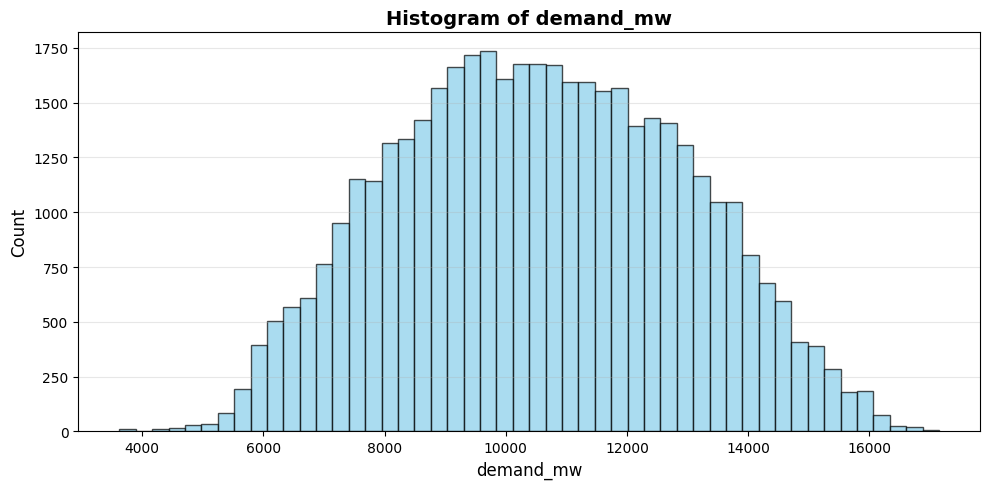


demand_mw Statistics:
  Count: 42611
  Mean: 10558.3922
  Std: 2369.6230
  Min: 3622.0000
  Max: 17150.0000
  Median: 10510.0000
--------------------------------------------------


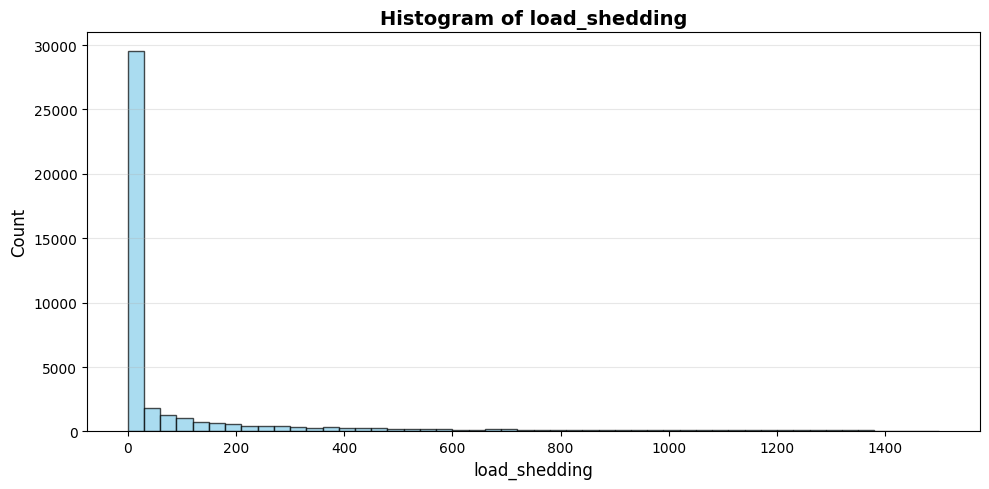


load_shedding Statistics:
  Count: 42611
  Mean: 118.9362
  Std: 274.9275
  Min: 0.0000
  Max: 1500.0000
  Median: 0.0000
--------------------------------------------------


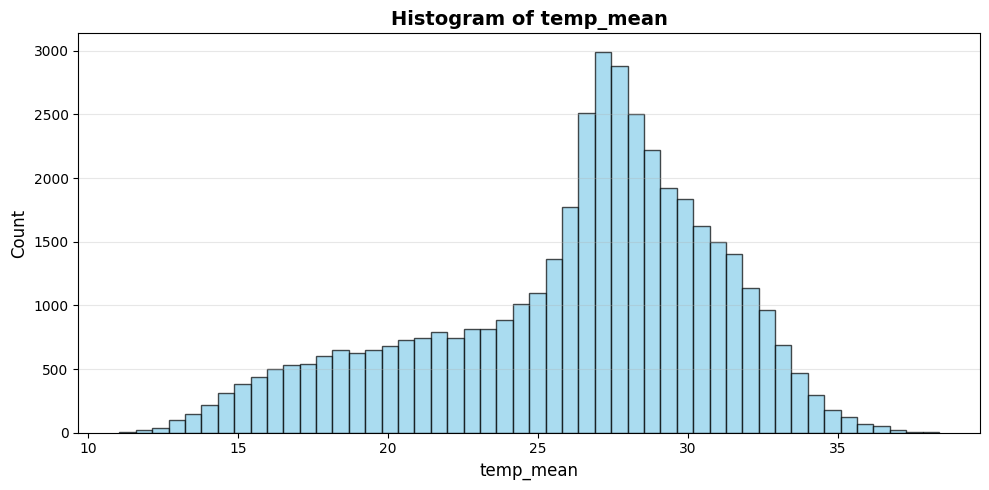


temp_mean Statistics:
  Count: 42611
  Mean: 26.1759
  Std: 4.8664
  Min: 11.0500
  Max: 38.3800
  Median: 27.2000
--------------------------------------------------


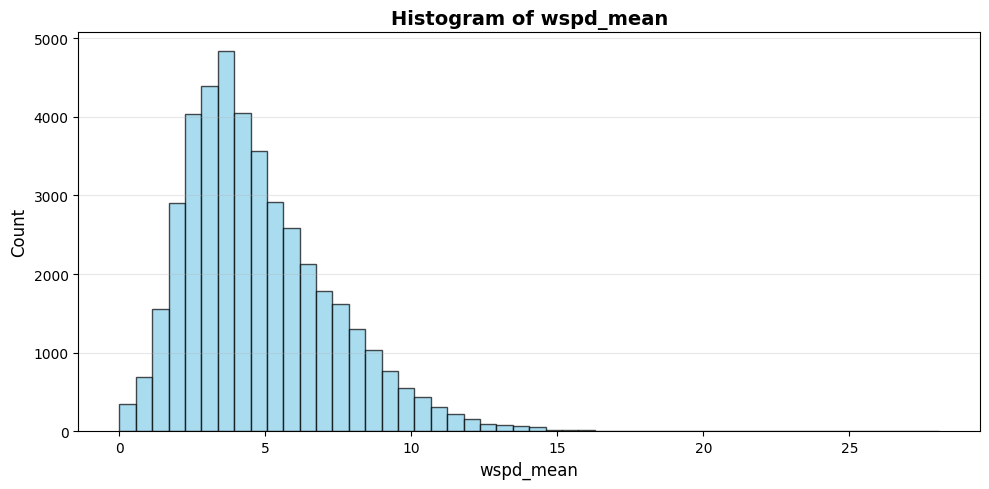


wspd_mean Statistics:
  Count: 42611
  Mean: 4.7860
  Std: 2.5642
  Min: 0.0000
  Max: 28.0700
  Median: 4.2700
--------------------------------------------------


In [36]:
import matplotlib.pyplot as plt

# Get numeric columns
numeric_cols = df_cleaned.select_dtypes(include=['number']).columns

# Create histogram for each column
for col in numeric_cols:
    plt.figure(figsize=(10, 5))
    plt.hist(df_cleaned[col], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
    plt.title(f'Histogram of {col}', fontsize=14, fontweight='bold')
    plt.xlabel(col, fontsize=12)
    plt.ylabel('Count', fontsize=12)
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\n{col} Statistics:")
    print(f"  Count: {df_cleaned[col].count()}")
    print(f"  Mean: {df_cleaned[col].mean():.4f}")
    print(f"  Std: {df_cleaned[col].std():.4f}")
    print(f"  Min: {df_cleaned[col].min():.4f}")
    print(f"  Max: {df_cleaned[col].max():.4f}")
    print(f"  Median: {df_cleaned[col].median():.4f}")
    print("-" * 50)



In [37]:
df_cleaned.shape[0], df_combined.shape[0]

(42611, 43526)

In [38]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 42611 entries, 2020-01-01 03:00:00 to 2025-12-31 23:00:00
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   demand_mw      42611 non-null  int64  
 1   load_shedding  42611 non-null  int64  
 2   temp_mean      42611 non-null  float64
 3   wspd_mean      42611 non-null  float64
dtypes: float64(2), int64(2)
memory usage: 1.6 MB


In [39]:
df_cleaned.to_csv('cleaned_combined_data.csv', index=True)

In [40]:
import pandas as pd

# Check the datetime index
print("Index type:", type(df_cleaned.index))
print("Start date:", df_cleaned.index.min())
print("End date:", df_cleaned.index.max())
print("Duplicate timestamps:", df_cleaned.index.has_duplicates)

# Count distinct hours available for each day
hours_per_day = (
    pd.Series(
        df_cleaned.index.hour,
        index=df_cleaned.index.normalize()
    )
    .groupby(level=0)
    .nunique()
)

# Show the results
print("\nMaximum distinct hours in any day:", hours_per_day.max())

print("\nNumber of days meeting each threshold:")
print("Exactly 24 hours:", (hours_per_day == 24).sum())
print("At least 23 hours:", (hours_per_day >= 23).sum())
print("At least 22 hours:", (hours_per_day >= 22).sum())
print("At least 21 hours:", (hours_per_day >= 21).sum())

print("\nDistribution of distinct hours per day:")
print(hours_per_day.value_counts().sort_index())

Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Start date: 2020-01-01 03:00:00
End date: 2025-12-31 23:00:00
Duplicate timestamps: False

Maximum distinct hours in any day: 23

Number of days meeting each threshold:
Exactly 24 hours: 0
At least 23 hours: 1589
At least 22 hours: 1677
At least 21 hours: 1706

Distribution of distinct hours per day:
datetime
1        1
2        4
3        4
4        6
5       15
6       65
7      251
8        4
9        5
10       1
11       6
12       3
13       3
14       5
15       7
16       6
17       7
18       8
19      10
20      15
21      29
22      88
23    1589
Name: count, dtype: int64


## Daily Completeness Filter for Time-Series Forecasting

Before training any time-series forecasting model, it is essential to ensure that the data has a consistent hourly structure. In our dataset, not all days contain a full 24-hour record. Some days start at 01:00 and end at 23:00, which means the 00:00 observation is missing. Other days contain only 22 hours or even fewer valid records. This creates irregular time intervals and breaks the continuity required for hourly forecasting.

For time-series modeling, a complete daily sequence is important because models depend on a regular index of timestamps to construct lag features, detect temporal patterns, and learn daily/weekly seasonality. If certain days are incomplete, the model may interpret missing hours as uneven spacing or may learn artificial patterns caused by data incompleteness rather than true demand behavior.

To address this issue, we applied a strict data-quality rule:

- We counted the number of valid hourly observations for each day.
- A day was considered usable only if it contained at least 23 hours of data.
- Days with fewer than 23 valid hourly records were removed from the dataset.

This filtering step ensures that only days with near-complete hourly coverage are retained. In other words, we kept only those days that have a full 23-hour sequence and discarded the remaining incomplete days. The result is a cleaner and more consistent dataset suitable for reliable time-series forecasting.

### Why this matters
Removing incomplete days helps to:
- maintain a regular hourly time index,
- avoid missing timestamp distortions,
- improve the reliability of lag-based features,
- reduce noise caused by partial-day records,
- support more stable model training and evaluation.

After this filtering process, the final dataset contains only complete daily records, making it much better suited for forecasting electricity demand in future time steps.

In [41]:
import pandas as pd

# Minimum number of distinct hours required per day
MIN_HOURS = 23  # Change to 23 or 21 if needed

# Ensure the index is a DatetimeIndex
if not isinstance(df_cleaned.index, pd.DatetimeIndex):
    raise TypeError("df_cleaned.index must be a pandas DatetimeIndex.")

# Create a temporary DataFrame
df_temp = df_cleaned.copy()

# Extract date and hour from the datetime index
df_temp["_date"] = df_temp.index.normalize()
df_temp["_hour"] = df_temp.index.hour

# Count the number of distinct hours available for each day
hours_per_day = df_temp.groupby("_date")["_hour"].nunique()

# Select dates that meet the minimum-hour requirement
valid_dates = hours_per_day[hours_per_day >= MIN_HOURS].index

# Keep all rows belonging to those dates
df_cleaned_min_hours = (
    df_temp[df_temp["_date"].isin(valid_dates)]
    .drop(columns=["_date", "_hour"])
    .copy()
)

# Display results
print("Original DataFrame shape:", df_cleaned.shape)
print("Filtered DataFrame shape:", df_cleaned_min_hours.shape)

print("Minimum required hours per day:", MIN_HOURS)
print("Number of retained days:", len(valid_dates))
print("Number of excluded days:", len(hours_per_day) - len(valid_dates))

# Verify the number of distinct hours per retained day
retained_hours = (
    df_cleaned_min_hours.index.to_series()
    .groupby(df_cleaned_min_hours.index.normalize())
    .apply(lambda timestamps: timestamps.dt.hour.nunique())
)

print("\nDistinct hours per retained day:")
print(retained_hours.value_counts().sort_index())

display(df_cleaned_min_hours.head(46))

Original DataFrame shape: (42611, 4)
Filtered DataFrame shape: (36547, 4)
Minimum required hours per day: 23
Number of retained days: 1589
Number of excluded days: 543

Distinct hours per retained day:
datetime
23    1589
Name: count, dtype: int64


,demand_mw,load_shedding,temp_mean,wspd_mean
datetime,,,,
2021-01-02 01:00:00,5834,0,13.78,3.12
2021-01-02 02:00:00,5418,0,15.42,4.00
2021-01-02 03:00:00,5244,0,17.17,2.78
2021-01-02 04:00:00,5153,0,19.65,3.20
2021-01-02 05:00:00,5154,0,21.50,2.88
2021-01-02 06:00:00,5490,0,23.98,5.00
2021-01-02 07:00:00,5622,0,24.27,4.68
2021-01-02 08:00:00,6015,0,24.45,4.38
2021-01-02 09:00:00,6226,0,25.23,4.28


In [42]:
df_cleaned_min_hours.to_csv('cleaned_min_hours_23.csv', index=True)

In [43]:
df_cleaned = df_cleaned_min_hours.copy()

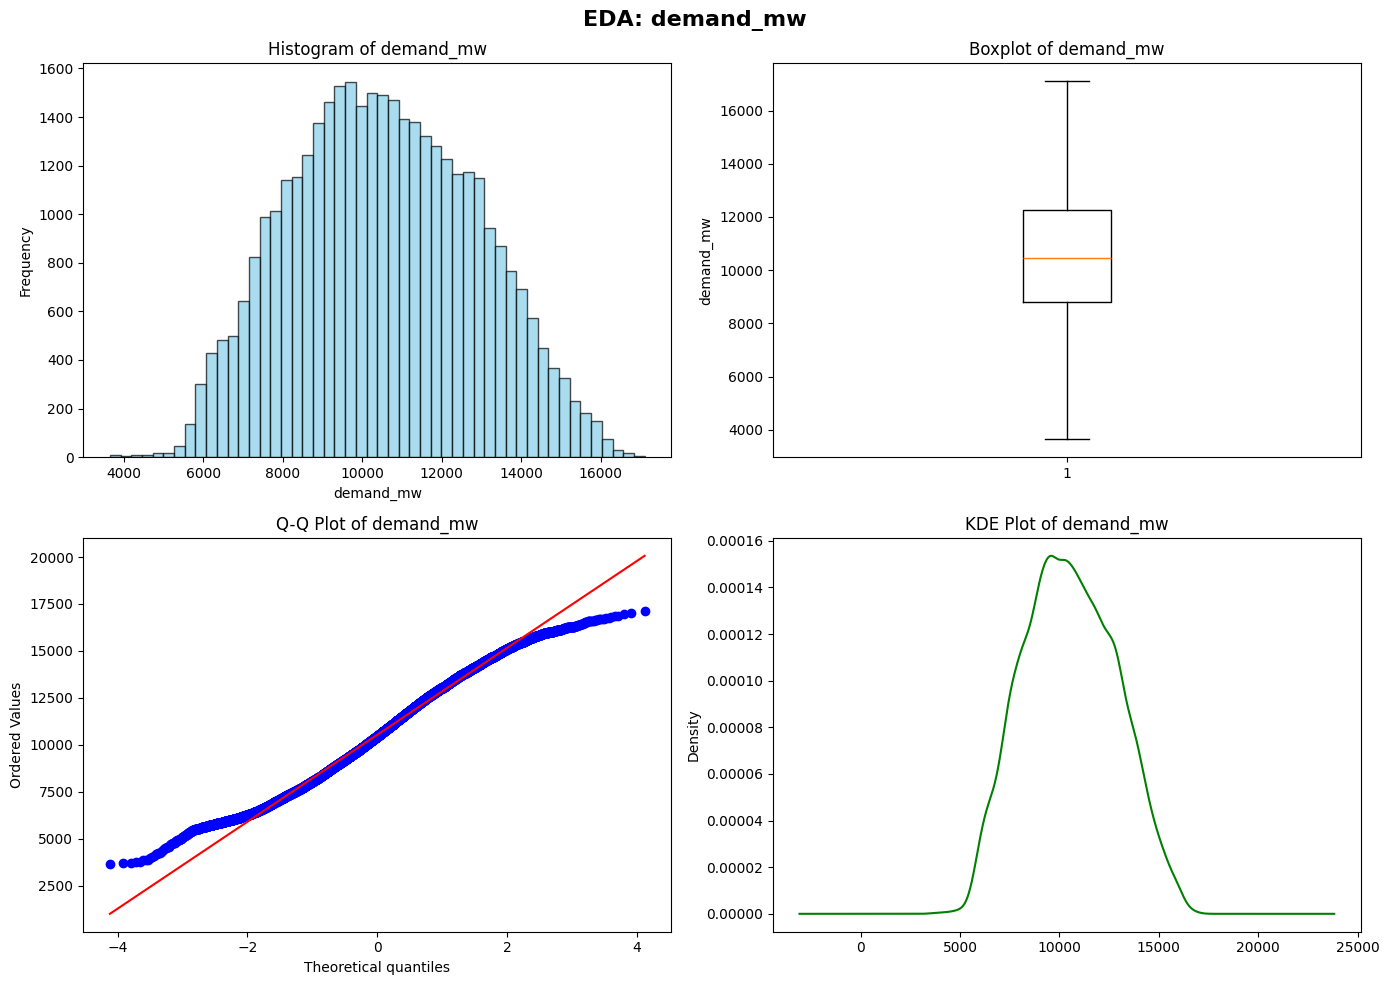


STATISTICS FOR demand_mw
Count: 36547
Mean: 10531.2286
Median: 10451.0000
Std Dev: 2323.9275
Min: 3651.0000
Max: 17100.0000
Q1 (25%): 8799.0000
Q3 (75%): 12265.0000
IQR: 3466.0000
Skewness: 0.0979
Kurtosis: -0.6435
Missing Values: 0


In [44]:
# EDA - demand_mw
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

col = 'demand_mw'  # Change this to the column you want to analyze
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'EDA: {col}', fontsize=16, fontweight='bold')

# Histogram
axes[0, 0].hist(df_cleaned[col], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_title(f'Histogram of {col}')
axes[0, 0].set_xlabel(col)
axes[0, 0].set_ylabel('Frequency')

# Boxplot
axes[0, 1].boxplot(df_cleaned[col])
axes[0, 1].set_title(f'Boxplot of {col}')
axes[0, 1].set_ylabel(col)

# Q-Q plot
stats.probplot(df_cleaned[col], dist="norm", plot=axes[1, 0])
axes[1, 0].set_title(f'Q-Q Plot of {col}')

# KDE plot
df_cleaned[col].plot(kind='kde', ax=axes[1, 1], color='green')
axes[1, 1].set_title(f'KDE Plot of {col}')

plt.tight_layout()
plt.show()

print(f"\n{'='*60}")
print(f"STATISTICS FOR {col}")
print(f"{'='*60}")
print(f"Count: {df_cleaned[col].count()}")
print(f"Mean: {df_cleaned[col].mean():.4f}")
print(f"Median: {df_cleaned[col].median():.4f}")
print(f"Std Dev: {df_cleaned[col].std():.4f}")
print(f"Min: {df_cleaned[col].min():.4f}")
print(f"Max: {df_cleaned[col].max():.4f}")
print(f"Q1 (25%): {df_cleaned[col].quantile(0.25):.4f}")
print(f"Q3 (75%): {df_cleaned[col].quantile(0.75):.4f}")
print(f"IQR: {df_cleaned[col].quantile(0.75) - df_cleaned[col].quantile(0.25):.4f}")
print(f"Skewness: {df_cleaned[col].skew():.4f}")
print(f"Kurtosis: {df_cleaned[col].kurtosis():.4f}")
print(f"Missing Values: {df_cleaned[col].isnull().sum()}")
print(f"{'='*60}")

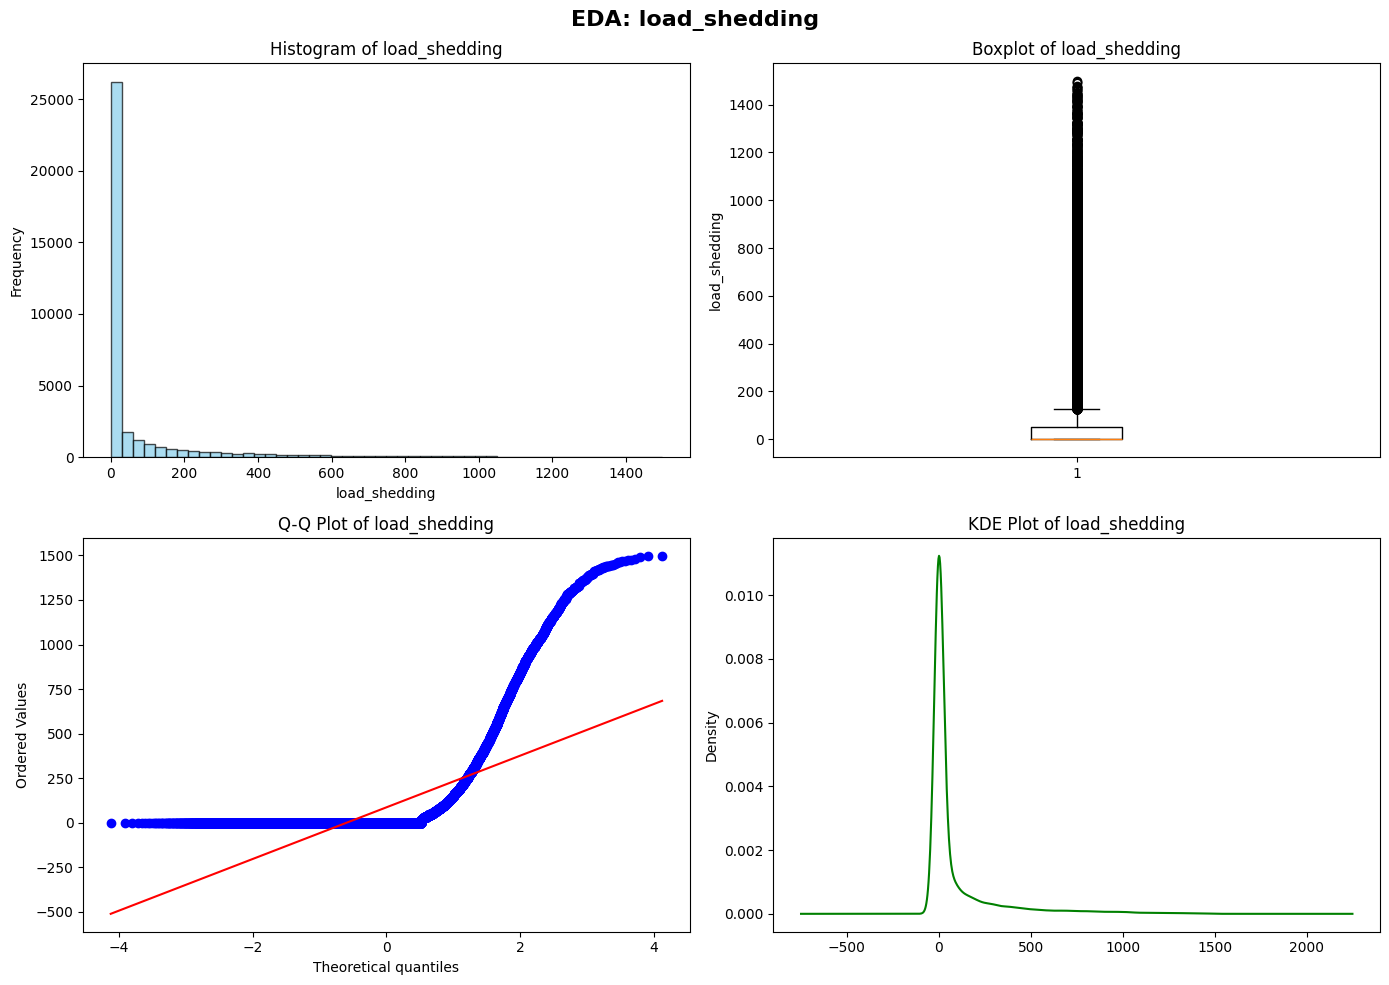


STATISTICS FOR load_shedding
Count: 36547
Mean: 85.8324
Median: 0.0000
Std Dev: 210.5459
Min: 0.0000
Max: 1498.0000
Q1 (25%): 0.0000
Q3 (75%): 50.0000
IQR: 50.0000
Skewness: 3.3490
Kurtosis: 12.1408
Missing Values: 0


In [45]:
# EDA - load_shedding
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

col = 'load_shedding'  # Change this to the column you want to analyze
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'EDA: {col}', fontsize=16, fontweight='bold')

# Histogram
axes[0, 0].hist(df_cleaned[col], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_title(f'Histogram of {col}')
axes[0, 0].set_xlabel(col)
axes[0, 0].set_ylabel('Frequency')

# Boxplot
axes[0, 1].boxplot(df_cleaned[col])
axes[0, 1].set_title(f'Boxplot of {col}')
axes[0, 1].set_ylabel(col)

# Q-Q plot
stats.probplot(df_cleaned[col], dist="norm", plot=axes[1, 0])
axes[1, 0].set_title(f'Q-Q Plot of {col}')

# KDE plot
df_cleaned[col].plot(kind='kde', ax=axes[1, 1], color='green')
axes[1, 1].set_title(f'KDE Plot of {col}')

plt.tight_layout()
plt.show()

print(f"\n{'='*60}")
print(f"STATISTICS FOR {col}")
print(f"{'='*60}")
print(f"Count: {df_cleaned[col].count()}")
print(f"Mean: {df_cleaned[col].mean():.4f}")
print(f"Median: {df_cleaned[col].median():.4f}")
print(f"Std Dev: {df_cleaned[col].std():.4f}")
print(f"Min: {df_cleaned[col].min():.4f}")
print(f"Max: {df_cleaned[col].max():.4f}")
print(f"Q1 (25%): {df_cleaned[col].quantile(0.25):.4f}")
print(f"Q3 (75%): {df_cleaned[col].quantile(0.75):.4f}")
print(f"IQR: {df_cleaned[col].quantile(0.75) - df_cleaned[col].quantile(0.25):.4f}")
print(f"Skewness: {df_cleaned[col].skew():.4f}")
print(f"Kurtosis: {df_cleaned[col].kurtosis():.4f}")
print(f"Missing Values: {df_cleaned[col].isnull().sum()}")
print(f"{'='*60}")

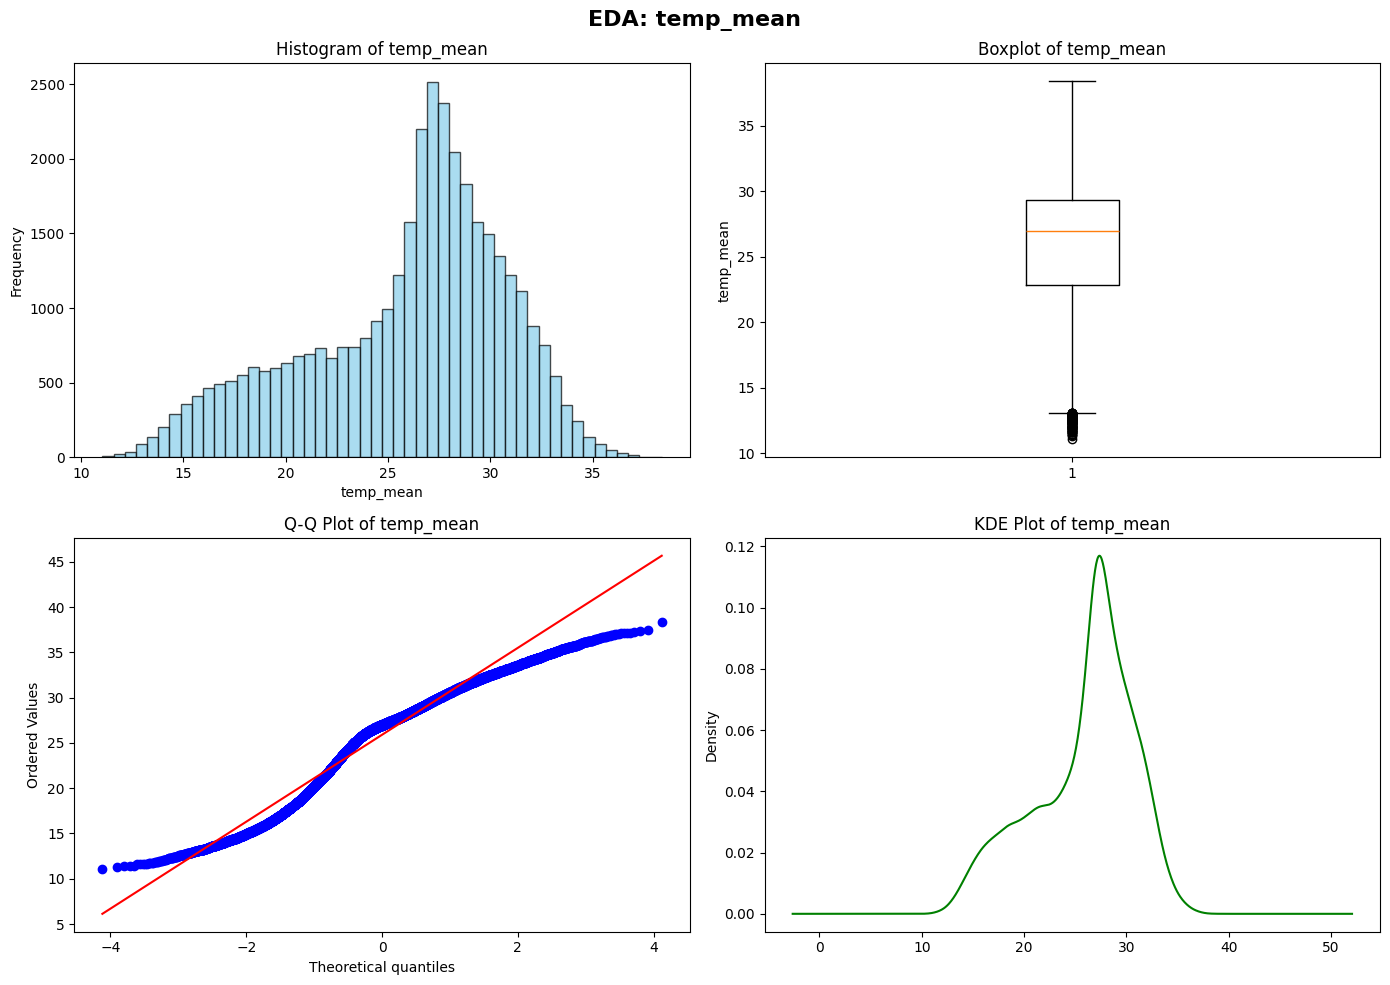


STATISTICS FOR temp_mean
Count: 36547
Mean: 25.9025
Median: 26.9800
Std Dev: 4.9059
Min: 11.0500
Max: 38.3800
Q1 (25%): 22.8200
Q3 (75%): 29.3300
IQR: 6.5100
Skewness: -0.6272
Kurtosis: -0.2700
Missing Values: 0


In [46]:
# EDA - temp_mean
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

col = 'temp_mean'  # Change this to the column you want to analyze
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'EDA: {col}', fontsize=16, fontweight='bold')

# Histogram
axes[0, 0].hist(df_cleaned[col], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_title(f'Histogram of {col}')
axes[0, 0].set_xlabel(col)
axes[0, 0].set_ylabel('Frequency')

# Boxplot
axes[0, 1].boxplot(df_cleaned[col])
axes[0, 1].set_title(f'Boxplot of {col}')
axes[0, 1].set_ylabel(col)

# Q-Q plot
stats.probplot(df_cleaned[col], dist="norm", plot=axes[1, 0])
axes[1, 0].set_title(f'Q-Q Plot of {col}')

# KDE plot
df_cleaned[col].plot(kind='kde', ax=axes[1, 1], color='green')
axes[1, 1].set_title(f'KDE Plot of {col}')

plt.tight_layout()
plt.show()

print(f"\n{'='*60}")
print(f"STATISTICS FOR {col}")
print(f"{'='*60}")
print(f"Count: {df_cleaned[col].count()}")
print(f"Mean: {df_cleaned[col].mean():.4f}")
print(f"Median: {df_cleaned[col].median():.4f}")
print(f"Std Dev: {df_cleaned[col].std():.4f}")
print(f"Min: {df_cleaned[col].min():.4f}")
print(f"Max: {df_cleaned[col].max():.4f}")
print(f"Q1 (25%): {df_cleaned[col].quantile(0.25):.4f}")
print(f"Q3 (75%): {df_cleaned[col].quantile(0.75):.4f}")
print(f"IQR: {df_cleaned[col].quantile(0.75) - df_cleaned[col].quantile(0.25):.4f}")
print(f"Skewness: {df_cleaned[col].skew():.4f}")
print(f"Kurtosis: {df_cleaned[col].kurtosis():.4f}")
print(f"Missing Values: {df_cleaned[col].isnull().sum()}")
print(f"{'='*60}")

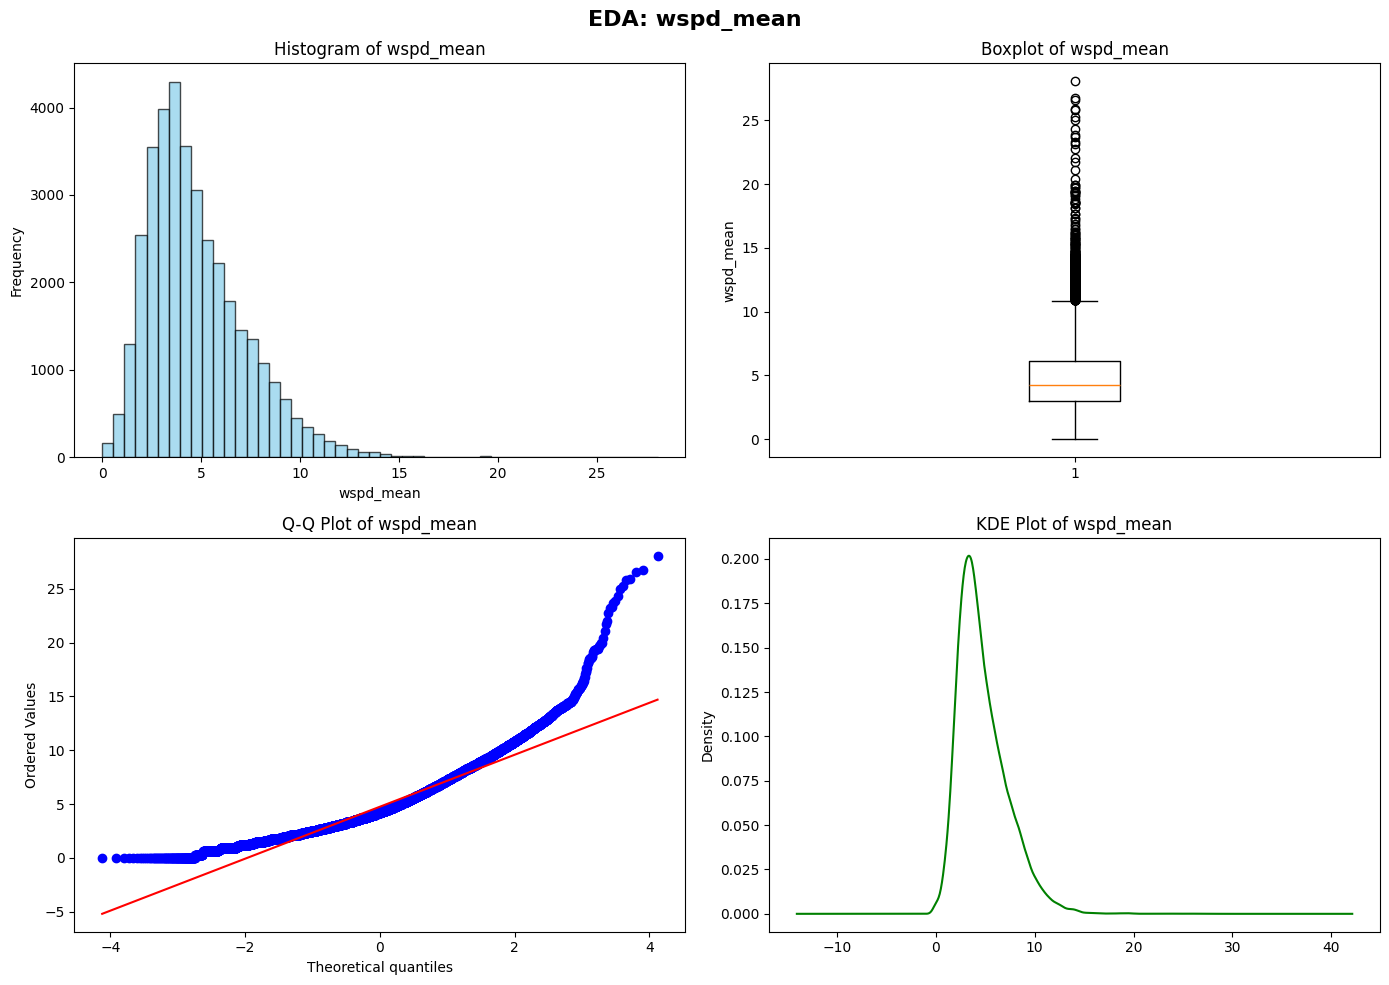


STATISTICS FOR wspd_mean
Count: 36547
Mean: 4.7580
Median: 4.2300
Std Dev: 2.5032
Min: 0.0000
Max: 28.0700
Q1 (25%): 2.9700
Q3 (75%): 6.1300
IQR: 3.1600
Skewness: 1.2134
Kurtosis: 3.0209
Missing Values: 0


In [47]:
# EDA - wspd_mean
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

col = 'wspd_mean'  # Change this to the column you want to analyze
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f'EDA: {col}', fontsize=16, fontweight='bold')

# Histogram
axes[0, 0].hist(df_cleaned[col], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_title(f'Histogram of {col}')
axes[0, 0].set_xlabel(col)
axes[0, 0].set_ylabel('Frequency')

# Boxplot
axes[0, 1].boxplot(df_cleaned[col])
axes[0, 1].set_title(f'Boxplot of {col}')
axes[0, 1].set_ylabel(col)

# Q-Q plot
stats.probplot(df_cleaned[col], dist="norm", plot=axes[1, 0])
axes[1, 0].set_title(f'Q-Q Plot of {col}')

# KDE plot
df_cleaned[col].plot(kind='kde', ax=axes[1, 1], color='green')
axes[1, 1].set_title(f'KDE Plot of {col}')

plt.tight_layout()
plt.show()

print(f"\n{'='*60}")
print(f"STATISTICS FOR {col}")
print(f"{'='*60}")
print(f"Count: {df_cleaned[col].count()}")
print(f"Mean: {df_cleaned[col].mean():.4f}")
print(f"Median: {df_cleaned[col].median():.4f}")
print(f"Std Dev: {df_cleaned[col].std():.4f}")
print(f"Min: {df_cleaned[col].min():.4f}")
print(f"Max: {df_cleaned[col].max():.4f}")
print(f"Q1 (25%): {df_cleaned[col].quantile(0.25):.4f}")
print(f"Q3 (75%): {df_cleaned[col].quantile(0.75):.4f}")
print(f"IQR: {df_cleaned[col].quantile(0.75) - df_cleaned[col].quantile(0.25):.4f}")
print(f"Skewness: {df_cleaned[col].skew():.4f}")
print(f"Kurtosis: {df_cleaned[col].kurtosis():.4f}")
print(f"Missing Values: {df_cleaned[col].isnull().sum()}")
print(f"{'='*60}")

In [47]:
df = pd.read_csv("cleaned_min_hours_23.csv")
df.shape

(36547, 5)

In [48]:
df.head(5)

,datetime,demand_mw,load_shedding,temp_mean,wspd_mean
0,2021-01-02 01:00:00,5834,0,13.78,3.12
1,2021-01-02 02:00:00,5418,0,15.42,4.00
2,2021-01-02 03:00:00,5244,0,17.17,2.78
3,2021-01-02 04:00:00,5153,0,19.65,3.20
4,2021-01-02 05:00:00,5154,0,21.50,2.88


In [49]:
df.columns

Index(['datetime', 'demand_mw', 'load_shedding', 'temp_mean', 'wspd_mean'], dtype='object')

In [50]:
# ============================================================
# RESEARCH PAPER VISUALIZATION SETUP
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import FuncFormatter

# Publication-friendly settings
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 600,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# Create output directory
import os
os.makedirs("paper_figures", exist_ok=True)

# Make a working dataframe
plot_df = df.copy()

plot_df["datetime"] = pd.to_datetime(plot_df["datetime"])
plot_df = plot_df.sort_values("datetime").reset_index(drop=True)

print(plot_df.shape)
print(plot_df["datetime"].min())
print(plot_df["datetime"].max())

(36547, 5)
2021-01-02 01:00:00
2025-12-31 23:00:00


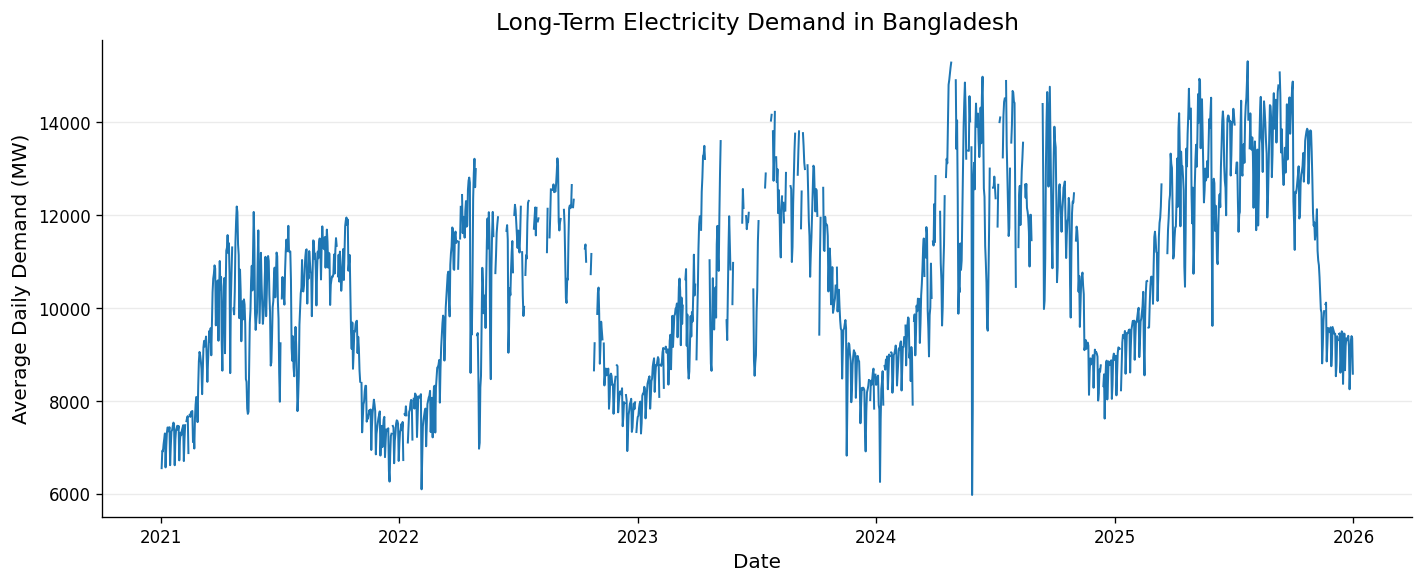

In [51]:
# ============================================================
# FIGURE 1 — LONG-TERM ELECTRICITY DEMAND
# ============================================================

daily_demand = (
    plot_df
    .set_index("datetime")["demand_mw"]
    .resample("D")
    .mean()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    daily_demand.index,
    daily_demand.values,
    linewidth=1.2
)

ax.set_title("Long-Term Electricity Demand in Bangladesh")
ax.set_xlabel("Date")
ax.set_ylabel("Average Daily Demand (MW)")

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    "paper_figures/Fig1_long_term_demand.png",
    bbox_inches="tight"
)

plt.show()

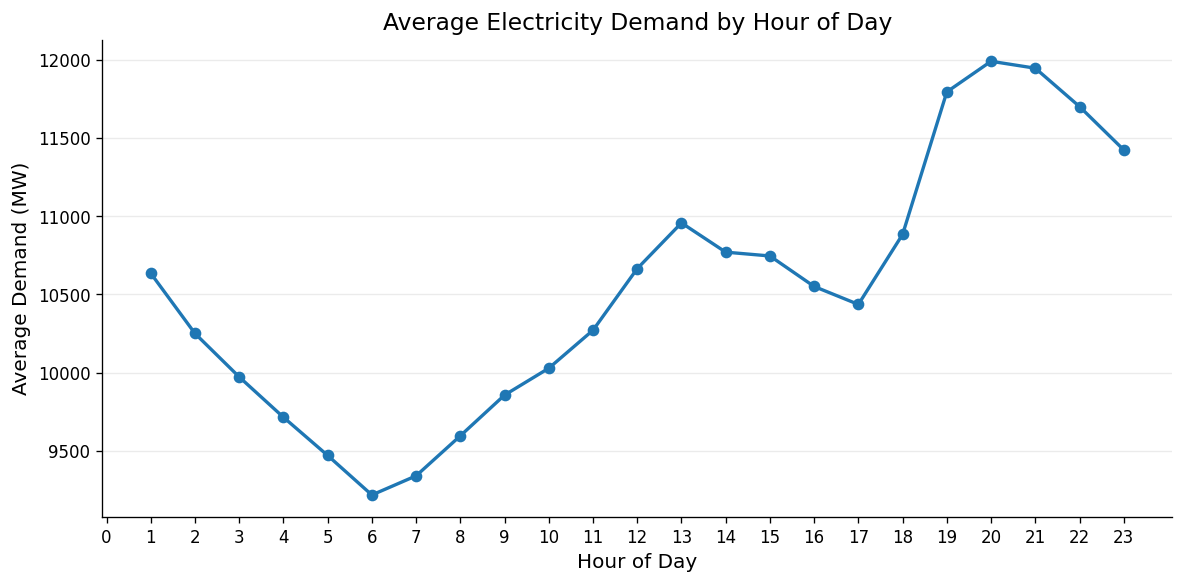

In [53]:
# ============================================================
# FIGURE 2 — HOURLY DEMAND PROFILE
# ============================================================

hourly_profile = (
    plot_df
    .groupby(plot_df["datetime"].dt.hour)["demand_mw"]
    .mean()
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    hourly_profile.index,
    hourly_profile.values,
    marker="o",
    linewidth=2
)

ax.set_title("Average Electricity Demand by Hour of Day")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Average Demand (MW)")

ax.set_xticks(range(24))

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    "paper_figures/Fig2_hourly_demand_profile.png",
    bbox_inches="tight"
)

plt.show()

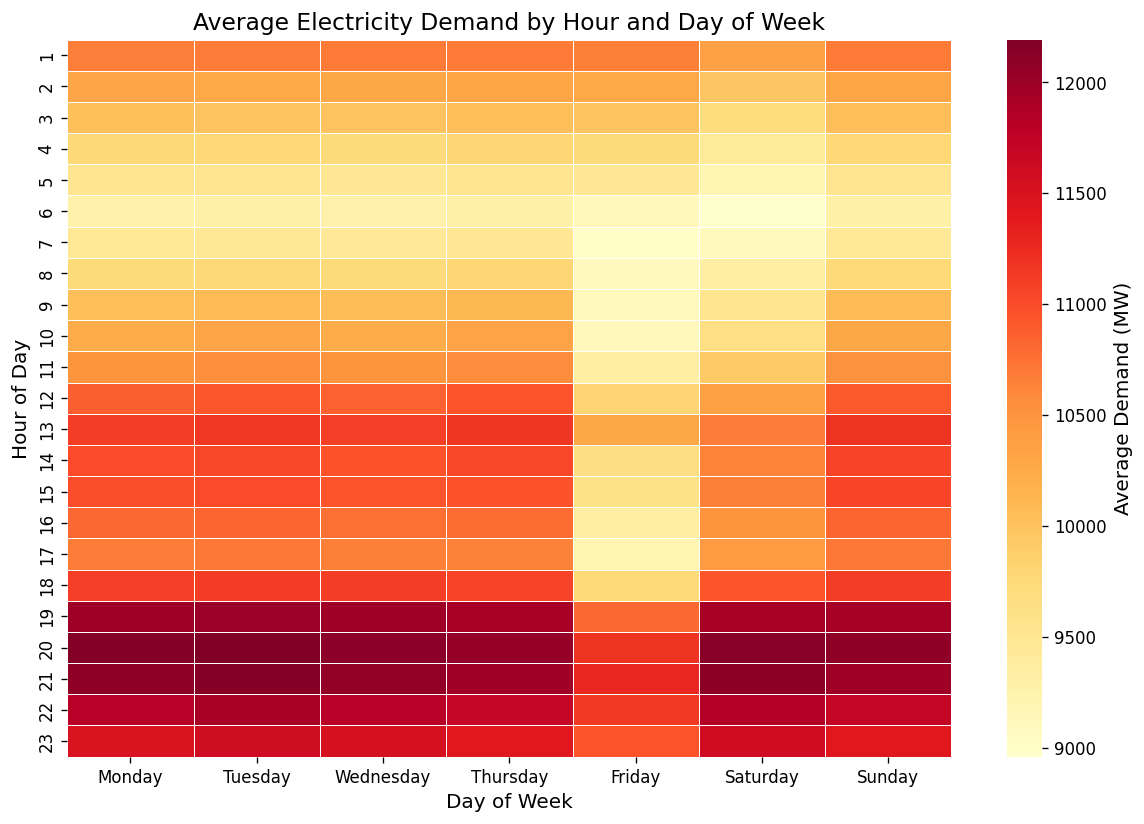

In [54]:
# ============================================================
# FIGURE 3 — WEEKLY SEASONALITY HEATMAP
# ============================================================

temp_heatmap = plot_df.copy()

temp_heatmap["hour"] = temp_heatmap["datetime"].dt.hour
temp_heatmap["dayofweek"] = temp_heatmap["datetime"].dt.dayofweek

day_names = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

heatmap_data = (
    temp_heatmap
    .pivot_table(
        index="hour",
        columns="dayofweek",
        values="demand_mw",
        aggfunc="mean"
    )
)

heatmap_data.columns = day_names

fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    linewidths=0.3,
    cbar_kws={"label": "Average Demand (MW)"},
    ax=ax
)

ax.set_title("Average Electricity Demand by Hour and Day of Week")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Hour of Day")

plt.tight_layout()

plt.savefig(
    "paper_figures/Fig3_hour_day_heatmap.png",
    bbox_inches="tight"
)

plt.show()

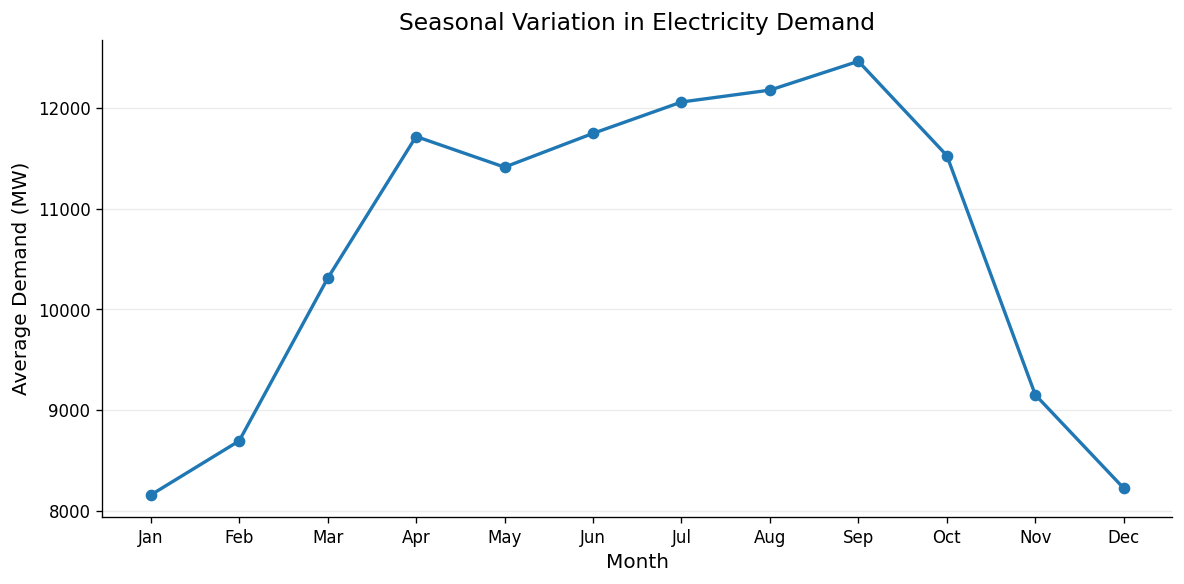

In [55]:
# ============================================================
# FIGURE 4 — MONTHLY SEASONAL PATTERN
# ============================================================

monthly_demand = (
    plot_df
    .groupby(plot_df["datetime"].dt.month)["demand_mw"]
    .mean()
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    range(1, 13),
    monthly_demand.values,
    marker="o",
    linewidth=2
)

ax.set_title("Seasonal Variation in Electricity Demand")
ax.set_xlabel("Month")
ax.set_ylabel("Average Demand (MW)")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    "paper_figures/Fig4_monthly_demand.png",
    bbox_inches="tight"
)

plt.show()

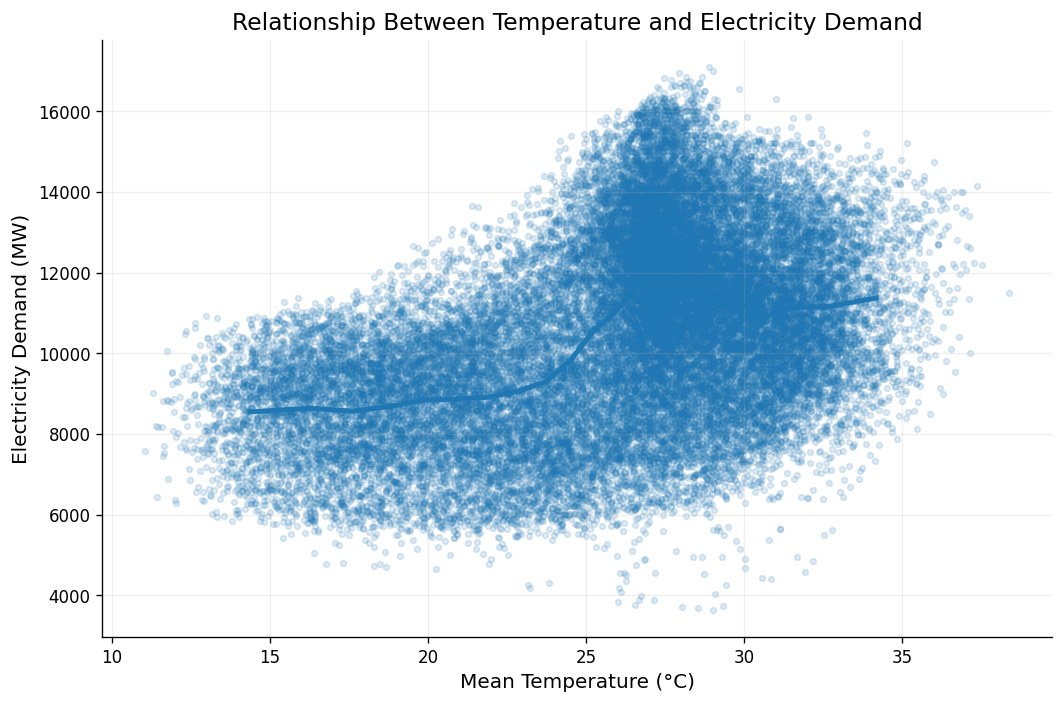

In [56]:
# ============================================================
# FIGURE 5 — TEMPERATURE VS ELECTRICITY DEMAND
# ============================================================

weather_df = plot_df[
    ["temp_mean", "demand_mw"]
].dropna()

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    weather_df["temp_mean"],
    weather_df["demand_mw"],
    alpha=0.15,
    s=12
)

# Add rolling/binned trend
binned = (
    weather_df
    .assign(temp_bin=pd.qcut(
        weather_df["temp_mean"],
        q=30,
        duplicates="drop"
    ))
    .groupby("temp_bin", observed=True)
    .agg(
        temp=("temp_mean", "mean"),
        demand=("demand_mw", "mean")
    )
)

ax.plot(
    binned["temp"],
    binned["demand"],
    linewidth=3
)

ax.set_title("Relationship Between Temperature and Electricity Demand")
ax.set_xlabel("Mean Temperature (°C)")
ax.set_ylabel("Electricity Demand (MW)")

ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    "paper_figures/Fig5_temperature_demand.png",
    bbox_inches="tight"
)

plt.show()

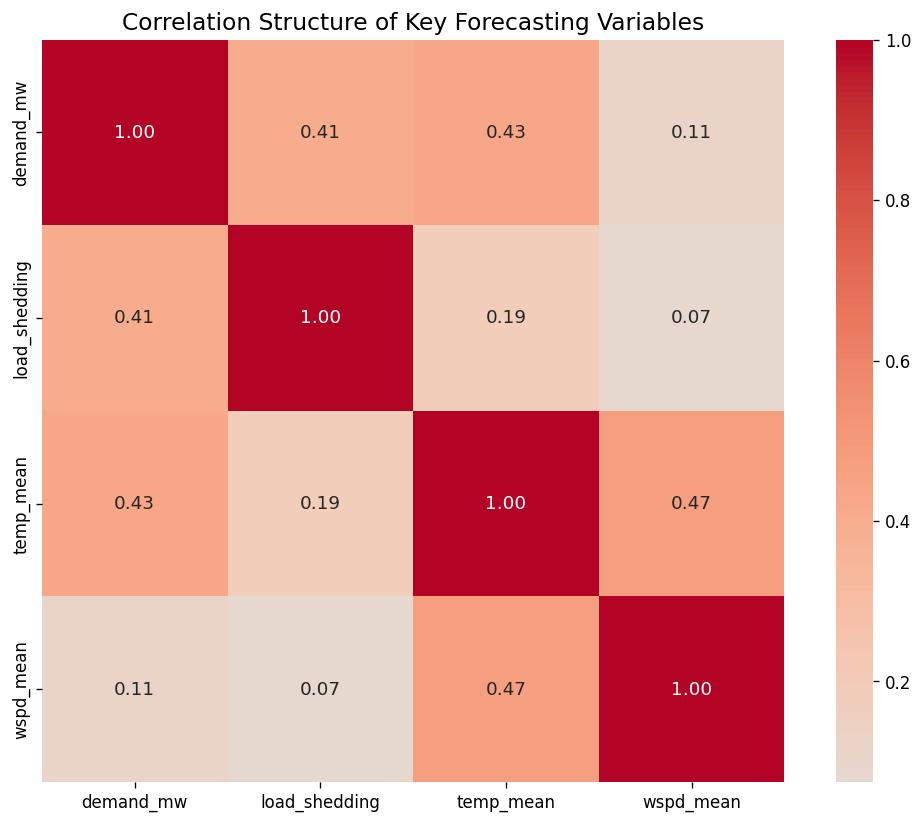

In [57]:
# ============================================================
# FIGURE 6 — CORRELATION HEATMAP
# ============================================================

corr_cols = [
    "demand_mw",
    "load_shedding",
    "temp_mean",
    "wspd_mean"
]

corr = plot_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    ax=ax
)

ax.set_title("Correlation Structure of Key Forecasting Variables")

plt.tight_layout()

plt.savefig(
    "paper_figures/Fig6_correlation_heatmap.png",
    bbox_inches="tight"
)

plt.show()

In [58]:
# Get timestamps from the datetime column or index
timestamps = (
    pd.to_datetime(df_cleaned["datetime"])
    if "datetime" in df_cleaned.columns
    else pd.to_datetime(df_cleaned.index)
)

# Restrict to 2021–2025 and ignore duplicate timestamps
start = pd.Timestamp("2021-01-01")
end = pd.Timestamp("2026-01-01")
actual = pd.DatetimeIndex(timestamps)
actual = actual[(actual >= start) & (actual < end)].unique()

# Compare observed timestamps with all expected hourly timestamps
expected = pd.date_range(start=start, end=end, freq="h")
expected_by_month = pd.Series(1, index=expected).groupby(expected.month).sum()
actual_by_month = pd.Series(1, index=actual).groupby(actual.month).sum()

monthly_missing = (
    expected_by_month
    .sub(actual_by_month, fill_value=0)
    .astype(int)
    .rename("missing_hours")
    .to_frame()
)

monthly_missing.index = monthly_missing.index.map(
    lambda month: pd.Timestamp(2000, month, 1).strftime("%B")
)

display(monthly_missing.sort_values("missing_hours", ascending=False))

month_with_most_missing = monthly_missing["missing_hours"].idxmax()
print(
    f"Month with the most missing hours (2021–2025): "
    f"{month_with_most_missing} — "
    f"{monthly_missing.loc[month_with_most_missing, 'missing_hours']:,} hours"
)

,missing_hours
June,955
July,937
August,868
September,771
October,730
April,702
May,569
March,477
December,362
January,317


Month with the most missing hours (2021–2025): June — 955 hours


In [59]:
# timestamps from datetime column or index
timestamps = (
    pd.to_datetime(df_cleaned["datetime"])
    if "datetime" in df_cleaned.columns
    else pd.to_datetime(df_cleaned.index)
)

# keep only 2021–2025
start_year = 2021
end_year = 2025
all_actual = pd.DatetimeIndex(timestamps)
all_actual = all_actual[(all_actual >= pd.Timestamp("2021-01-01")) &
                        (all_actual < pd.Timestamp("2026-01-01"))].unique()

yearly_report = []

for year in range(start_year, end_year + 1):
    year_start = pd.Timestamp(f"{year}-01-01")
    year_end = pd.Timestamp(f"{year + 1}-01-01")

    actual = all_actual[(all_actual >= year_start) & (all_actual < year_end)]

    # expected hourly timestamps for that full year
    expected = pd.date_range(
        start=year_start,
        end=year_end - pd.Timedelta(hours=1),
        freq="H"
    )

    missing = expected.difference(actual)
    extra = actual.difference(expected)

    yearly_report.append({
        "year": year,
        "expected_count": len(expected),
        "observed_count": len(actual),
        "missing_count": len(missing),
        "extra_count": len(extra),
        "missing_hours": missing[:10],   # first 10 examples
        "extra_hours": extra[:10],       # first 10 examples
    })

for row in yearly_report:
    print(f"Year {row['year']}: "
          f"expected={row['expected_count']}, "
          f"observed={row['observed_count']}, "
          f"missing={row['missing_count']}, "
          f"extra={row['extra_count']}")

Year 2021: expected=8760, observed=8211, missing=549, extra=0
Year 2022: expected=8760, observed=6578, missing=2182, extra=0
Year 2023: expected=8760, observed=6647, missing=2113, extra=0
Year 2024: expected=8784, observed=7084, missing=1700, extra=0
Year 2025: expected=8760, observed=8027, missing=733, extra=0


C:\Users\Md Mahfuzur Rahman\AppData\Local\Temp\ipykernel_2240\2044376423.py:24: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  expected = pd.date_range(


In [60]:
yearly_df = pd.DataFrame(yearly_report)
print(yearly_df)

   year  expected_count  observed_count  missing_count  extra_count  \
0  2021            8760            8211            549            0   
1  2022            8760            6578           2182            0   
2  2023            8760            6647           2113            0   
3  2024            8784            7084           1700            0   
4  2025            8760            8027            733            0   

                                       missing_hours  \
0  DatetimeIndex(['2021-01-01 00:00:00', '2021-01...   
1  DatetimeIndex(['2022-01-01 00:00:00', '2022-01...   
2  DatetimeIndex(['2023-01-01', '2023-01-02', '20...   
3  DatetimeIndex(['2024-01-01', '2024-01-02', '20...   
4  DatetimeIndex(['2025-01-01 00:00:00', '2025-01...   

                                         extra_hours  
0  DatetimeIndex([], dtype='datetime64[ns]', freq...  
1  DatetimeIndex([], dtype='datetime64[ns]', freq...  
2  DatetimeIndex([], dtype='datetime64[ns]', freq...  
3  DatetimeIndex